In [39]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [40]:
url = "https://raw.githubusercontent.com/RZajacUE/ZPA26-27Gr5/main/data/cechy_kluczowe.csv"

df = pd.read_csv(
    url,
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

print("Liczba wierszy:", len(df))
print("Kolumny:", df.columns.tolist())

df.head(10)

Liczba wierszy: 112
Kolumny: ['Produkt', 'rok', 'cena', 'typ', 'cena_lag1', 'zmiana_roczna_proc', 'indeks_2019_100', 'srednia_poprzednich_3_lat', 'roznica_dynamiki_vs_paliwa_pp']


,Produkt,rok,cena,typ,cena_lag1,zmiana_roczna_proc,indeks_2019_100,srednia_poprzednich_3_lat,roznica_dynamiki_vs_paliwa_pp
0,ONEkodiesel,2019,4.02625,paliwo,NaN,NaN,100.000000,NaN,NaN
1,ONEkodiesel,2020,3.34900,paliwo,4.02625,-16.820863,83.179137,NaN,-2.923774
2,ONEkodiesel,2021,4.22825,paliwo,3.34900,26.254106,105.017075,3.687625,-0.823410
3,ONEkodiesel,2022,6.69225,paliwo,4.22825,58.274700,166.215461,3.867833,13.836137
4,ONEkodiesel,2023,5.12700,paliwo,6.69225,-23.388995,127.339336,4.756500,-6.335957
5,ONEkodiesel,2024,4.98450,paliwo,5.12700,-2.779403,123.800062,5.349167,0.011045
6,ONEkodiesel,2025,4.66350,paliwo,4.98450,-6.439964,115.827383,5.601250,1.296098
7,Pb95,2019,3.91150,paliwo,NaN,NaN,100.000000,NaN,NaN
8,Pb95,2020,3.43075,paliwo,3.91150,-12.290681,87.709319,NaN,1.606408
9,Pb95,2021,4.36150,paliwo,3.43075,27.129636,111.504538,3.671125,0.052121


In [41]:
target = "cena"

numeric_features = [
    "cena_lag1",
    "srednia_poprzednich_3_lat"
]

categorical_features = [
    "Produkt",
    "typ"
]

features = numeric_features + categorical_features

def create_model():
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="median"), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ]
    )

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression())
    ])

    return model

print("Model regresji liniowej przygotowany do walidacji walk-forward.")

Model regresji liniowej przygotowany do walidacji walk-forward.


In [42]:
podzialy = [
    (2021, 2022),
    (2022, 2023),
    (2023, 2024),
    (2024, 2025)
]

wyniki = []
prognozy = []

for koniec_treningu, rok_testowy in podzialy:

    # Chronologiczny podział danych
    train = df[df["rok"] <= koniec_treningu].copy()
    test = df[df["rok"] == rok_testowy].copy()

    train = train.dropna(subset=[target, "cena_lag1"])
    test = test.dropna(subset=[target, "cena_lag1"])

    X_train = train[features]
    y_train = train[target]
    X_test = test[features]
    y_test = test[target]

    # Prognoza bazowa i regresja liniowa
    baseline_predictions = test["cena_lag1"]

    model = create_model()
    model.fit(X_train, y_train)
    regression_predictions = model.predict(X_test)

    # Zapis prognoz dla poszczególnych grup
    for nazwa, predykcje in [
        ("Baseline", baseline_predictions),
        ("Regresja liniowa", regression_predictions)
    ]:
        for typ, rzeczywista, prognoza in zip(
            test["typ"], y_test, predykcje
        ):
            prognozy.append({
                "Rok testowy": rok_testowy,
                "Typ": typ,
                "Model": nazwa,
                "Cena rzeczywista": rzeczywista,
                "Prognoza": prognoza
            })

    # Ocena jakości prognoz
    for nazwa, predykcje in [
        ("Baseline", baseline_predictions),
        ("Regresja liniowa", regression_predictions)
    ]:
        wyniki.append({
            "Rok testowy": rok_testowy,
            "Model": nazwa,
            "MAE": mean_absolute_error(y_test, predykcje),
            "RMSE": np.sqrt(mean_squared_error(y_test, predykcje)),
            "R2": r2_score(y_test, predykcje)
        })

wyniki_df = pd.DataFrame(wyniki)
prognozy_df = pd.DataFrame(prognozy)

print("WYNIKI WALIDACJI WALK-FORWARD:")
print(wyniki_df.to_string(index=False))

print("\nLICZBA PROGNOZ WEDŁUG GRUP:")
print(prognozy_df.groupby(["Typ", "Model"]).size())

WYNIKI WALIDACJI WALK-FORWARD:
 Rok testowy            Model      MAE     RMSE       R2
        2022         Baseline 1.725594 2.179679 0.957585
        2022 Regresja liniowa 1.801807 2.239472 0.955226
        2023         Baseline 1.492953 2.094060 0.970597
        2023 Regresja liniowa 1.214447 1.542158 0.984053
        2024         Baseline 0.636484 0.964039 0.994391
        2024 Regresja liniowa 0.950928 1.229753 0.990873
        2025         Baseline 0.788016 1.269190 0.991285
        2025 Regresja liniowa 0.819792 1.069153 0.993816

LICZBA PROGNOZ WEDŁUG GRUP:
Typ      Model           
paliwo   Baseline            12
         Regresja liniowa    12
żywność  Baseline            52
         Regresja liniowa    52
dtype: int64


In [43]:
podsumowanie = wyniki_df.groupby("Model").agg(
    srednie_MAE=("MAE", "mean"),
    srednie_RMSE=("RMSE", "mean"),
    srednie_R2=("R2", "mean")
).round(4)

print("PODSUMOWANIE WALIDACJI WALK-FORWARD:")
print(podsumowanie)

PODSUMOWANIE WALIDACJI WALK-FORWARD:
                  srednie_MAE  srednie_RMSE  srednie_R2
Model                                                  
Baseline               1.1608        1.6267      0.9785
Regresja liniowa       1.1967        1.5201      0.9810


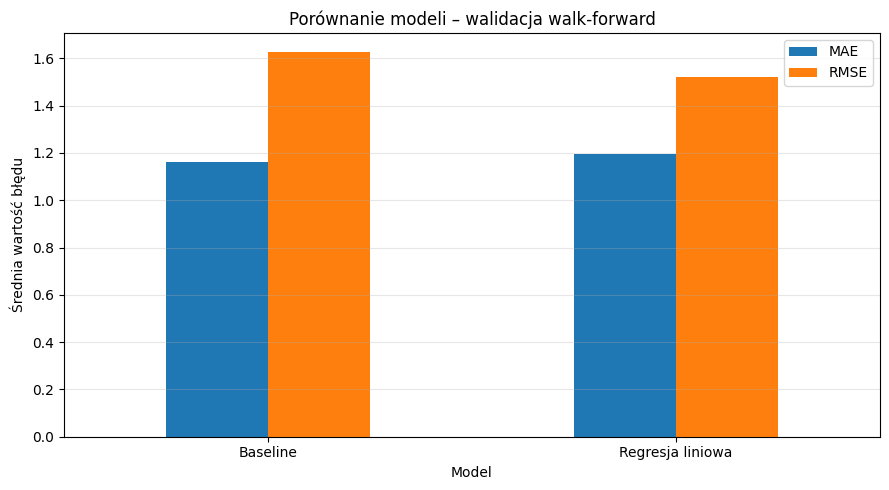

In [44]:
import matplotlib.pyplot as plt

podsumowanie[["srednie_MAE", "srednie_RMSE"]].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Porównanie modeli – walidacja walk-forward")
plt.xlabel("Model")
plt.ylabel("Średnia wartość błędu")
plt.legend(["MAE", "RMSE"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [45]:
print(df["typ"].value_counts())

typ
żywność    91
paliwo     21
Name: count, dtype: int64


In [46]:
wyniki_grup = []

for (typ, model), grupa in prognozy_df.groupby(["Typ", "Model"]):
    wyniki_grup.append({
        "Typ": typ,
        "Model": model,
        "MAE": mean_absolute_error(
            grupa["Cena rzeczywista"], grupa["Prognoza"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            grupa["Cena rzeczywista"], grupa["Prognoza"]
        )),
        "R2": r2_score(
            grupa["Cena rzeczywista"], grupa["Prognoza"]
        )
    })

wyniki_grup_df = pd.DataFrame(wyniki_grup)

print("WYNIKI WALIDACJI WEDŁUG GRUP:")
print(wyniki_grup_df.round(4).to_string(index=False))

WYNIKI WALIDACJI WEDŁUG GRUP:
    Typ            Model    MAE   RMSE      R2
 paliwo         Baseline 0.8941 1.1630 -2.2277
 paliwo Regresja liniowa 1.2599 1.4813 -4.2366
żywność         Baseline 1.2223 1.8112  0.9818
żywność Regresja liniowa 1.1822 1.6080  0.9856


In [47]:
wyniki_df.to_csv(
    "wyniki_walk_forward.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    index=False
)

podsumowanie.to_csv(
    "podsumowanie_walk_forward.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

wyniki_grup_df.to_csv(
    "wyniki_walk_forward_grupy.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    index=False
)

print("Wyniki walidacji zostały zapisane.")

Wyniki walidacji zostały zapisane.


### Wnioski z walidacji walk-forward

Przeprowadzono walidację walk-forward na danych z lat 2019-2025. Wykorzystano cztery kolejne okresy testowe (2022-2025), zachowując chronologiczną kolejność obserwacji. W każdym kroku model regresji liniowej trenowano ponownie na danych z wcześniejszych lat, a następnie oceniano jego prognozy dla kolejnego roku.

Model regresji liniowej porównano z modelem bazowym (baseline), który jako prognozę przyjmuje cenę produktu z poprzedniego roku. Jako miary jakości prognoz zastosowano MAE, RMSE oraz współczynnik determinacji R².

**Średnie wyniki walidacji walk-forward:**

| Model | MAE | RMSE | R² |
|---|---:|---:|---:|
| Baseline | 1,1608 | 1,6267 | 0,9785 |
| Regresja liniowa | 1,1967 | 1,5201 | 0,9810 |

Baseline uzyskał niższe średnie MAE, natomiast regresja liniowa osiągnęła niższe średnie RMSE i wyższe R². Oznacza to, że żaden z modeli nie był jednoznacznie lepszy we wszystkich zastosowanych metrykach.

**Wyniki w podziale na żywność i paliwa:**

| Grupa | Model | MAE | RMSE | R² |
|---|---|---:|---:|---:|
| Paliwo | Baseline | 0,8941 | 1,1630 | -2,2277 |
| Paliwo | Regresja liniowa | 1,2599 | 1,4813 | -4,2366 |
| Żywność | Baseline | 1,2223 | 1,8112 | 0,9818 |
| Żywność | Regresja liniowa | 1,1822 | 1,6080 | 0,9856 |

W przypadku produktów spożywczych regresja liniowa uzyskała lepsze wyniki niż baseline we wszystkich trzech metrykach. Dla paliw lepsze rezultaty osiągnął model bazowy. Ujemne wartości R² dla paliw wskazują na słabą jakość prognoz względem przewidywania średniej ceny w ocenianym zbiorze.

Wyniki należy interpretować ostrożnie ze względu na krótki okres obserwacji (2019-2025) oraz różne skale cen analizowanych produktów. Ponadto obecny model nie pozwala bezpośrednio ocenić, czy ceny paliw poprawiają prognozowanie cen żywności, ponieważ nie wykorzystuje cen paliw jako zmiennych objaśniających ceny produktów spożywczych.

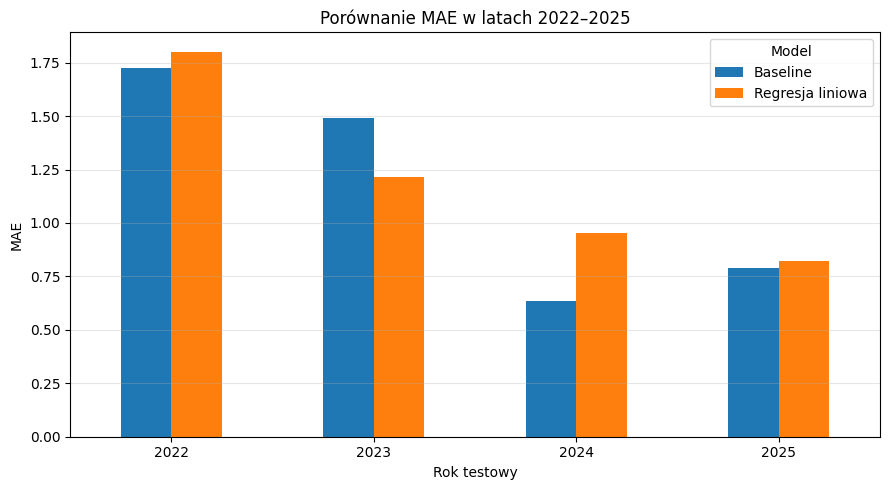

In [48]:
dane_wykres = wyniki_df.pivot(
    index="Rok testowy",
    columns="Model",
    values="MAE"
)

dane_wykres.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Porównanie MAE w latach 2022–2025")
plt.xlabel("Rok testowy")
plt.ylabel("MAE")
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

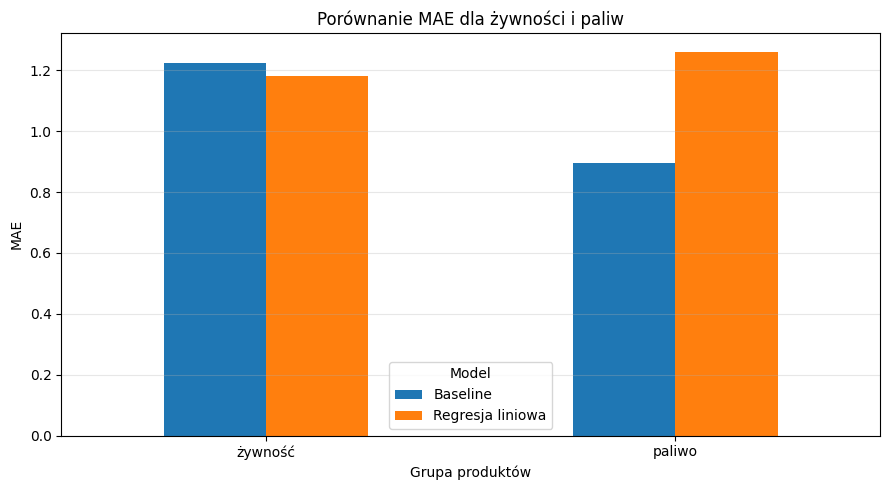

In [49]:
dane_grupy = wyniki_grup_df.pivot(
    index="Typ",
    columns="Model",
    values="MAE"
)

dane_grupy = dane_grupy.reindex(["żywność", "paliwo"])

dane_grupy.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Porównanie MAE dla żywności i paliw")
plt.xlabel("Grupa produktów")
plt.ylabel("MAE")
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()